In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Retrieve a simulated 1 fs deep-UV trace: dispersion in the medium matters.

The dataset (``examples/data/tgfrog_sim_1fs_uvfs.h5``) is a reduced cut of the
first-principles 3D TG-FROG instrument simulation made with ModelPNPS.jl
(https://github.com/LupoLab/ModelPNPS.jl): a transform-limited 1 fs pulse at
260 nm, measured through 4, 9.5 and 40 um of fused silica and a 0.5 mm
collection hole. Nothing in the trace comes from croak's own forward model: the
dispersion, phase matching, geometric smearing and chromatic collection all come
out of the instrument simulation.

At each thickness the trace is retrieved twice:

* with the **extended model**: dispersive propagation through the substrate
  plus the geometric BOXCARS smearing kernel, and
* with the **standard thin-medium model** that conventional FROG codes use.

The reference pulse is the mask-vignetted gate beamlet stored in the file
(1.03 fs). Both models fit the trace well (trace errors below 0.5 %), but only
the extended model returns the right pulse: the script prints 1.10–1.13 fs at
every thickness. The standard model absorbs the unmodelled substrate dispersion
into the pulse and broadens with thickness, from 1.60 fs at 4 um to 2.44 fs at
40 um (about 2.4 times the reference) while its trace error stays at 0.43 %: the
trace error alone does not certify a retrieval.

The preprocessing here (defringing, a fixed fourth-power spectral correction,
the integrated beamlet spectrum, fitted delay zero) is a teaching set-up; the
papers' validation uses a different protocol, described in the manual's
validation chapter.

Run::

    uv run python examples/example_paper_thickness.py

Takes a couple of minutes (six retrievals). Writes ``paper_thickness.png``.
"""

from __future__ import annotations

import matplotlib
import numpy as np

matplotlib.use("Agg")

import matplotlib.pyplot as plt  # noqa: E402 - must follow matplotlib.use above

import croak  # noqa: E402 - imports pyplot transitively
from croak.session import (  # noqa: E402 - see note above
    PreprocParams,
    RetrieveParams,
    SimulatedLoadParams,
    assemble_simulated_load_data,
    build_tracedata,
    run_retrieval,
)
from croak.truth_metrics import truth_errors  # noqa: E402 - see note above

DATA = "examples/data/tgfrog_sim_1fs_uvfs.h5"
THICKNESSES_UM = [4.0, 9.5, 40.0]
REFERENCE_FWHM_FS = 1.03  # the stored mask-vignetted gate beamlet (data README)

# The retrieval band and delay window used for this comparison. The
# scan's delay axis has a uniform 0.25 fs core to +-25 fs and coarser wing
# points beyond; the crop keeps the core, which the smearing kernel's
# delay-axis convolution needs.
PREPROC = PreprocParams(
    lam_min_nm=131.0,
    lam_max_nm=793.0,
    lam_bound_min_nm=65.5,
    lam_bound_max_nm=1189.5,
    trange_fs=100.0,
    tau_min_fs=-25.0,
    tau_max_fs=25.0,
    lamm_min_nm=131.0,
    lamm_max_nm=793.0,
    lamm_bound_min_nm=131.0,
    lamm_bound_max_nm=793.0,
    taum_min_fs=-25.0,
    taum_max_fs=25.0,
    tau_bound_min_fs=-25.0,
    tau_bound_max_fs=25.0,
    defringe=True,
)


def load(z_um: float):
    """Load one thickness slice, referenced to the gating beamlet spectrum."""
    sim = SimulatedLoadParams(
        frog_path=DATA,
        z_thickness_um=z_um,
        lam_min_nm=131.0,
        third_order=True,
        third_order_exp=4.0,  # fixed; the marginal-check Auto refines it per trace
        use_spectrum=True,
        spectrum_source="beamlet",
    )
    data = assemble_simulated_load_data(sim)
    return data, build_tracedata(PREPROC, data)


def retrieve(td, z_um: float, extended: bool):
    """Run one seeded retrieval with the extended or the thin-medium model."""
    rp = RetrieveParams(
        solver="warm-lbfgs",
        maxiters=300,
        perfect_init=True,
        perfect_init_fs=1.0,
        dispersive=extended,
        material="SiO2",  # Malitson Sellmeier, as in the simulation
        thickness_um=z_um,
        npoints=max(1, round(z_um)),  # one depth node per micrometre
        smearing=extended,
        smear_hole_diameter_mm=1.0,  # the simulated BOXCARS mask geometry
        smear_hole_spacing_mm=1.0,
        fit_tau0=True,
    )
    return run_retrieval(rp, td, rng=np.random.default_rng(0))


def main() -> None:
    """Run both models at every thickness and plot the comparison."""
    results: dict[str, list] = {"extended": [], "standard": []}
    reference = None  # the stored gate-beamlet reference pulse
    for z in THICKNESSES_UM:
        data, td = load(z)
        reference = data["truth"]
        for label in ("extended", "standard"):
            res = retrieve(td, z, extended=(label == "extended"))
            pr = croak.process_result(res, measured=td.trace)
            errs = truth_errors(res, reference)
            results[label].append((z, res, pr))
            print(
                f"z = {z:5.1f} um  {label:8s}  R = {100 * res.error:.3f}%  "
                f"FWHM = {pr.fwhm_retr * 1e15:.2f} fs  "
                f"eps_It = {errs.eps_It:.3f}"
            )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")

    # Retrieved duration against thickness, with the reference pulse duration.
    for label, marker in (("extended", "o"), ("standard", "s")):
        zs = [z for z, _, _ in results[label]]
        fw = [pr.fwhm_retr * 1e15 for _, _, pr in results[label]]
        ax1.plot(zs, fw, marker + "-", label=f"{label} model")
    ax1.axhline(REFERENCE_FWHM_FS, color="k", ls=":", label="reference pulse")
    ax1.set_xlabel("substrate thickness (um)")
    ax1.set_ylabel("retrieved FWHM (fs)")
    ax1.legend()

    # Temporal intensity at the thickest substrate, over the reference pulse.
    assert reference is not None
    ax2.fill_between(
        reference.t * 1e15, reference.It, color="0.8", label="reference pulse"
    )
    for label, style in (("extended", "-"), ("standard", "--")):
        _, res, pr = results[label][-1]
        # centre the retrieved peak at t = 0, the reference's convention (a pure
        # time translation, which the trace does not determine)
        t0 = pr.t_over[pr.It_retr.argmax()]
        ax2.plot((pr.t_over - t0) * 1e15, pr.It_retr, style, label=f"{label} model")
    ax2.set_xlim(-8, 8)
    ax2.set_xlabel("time (fs)")
    ax2.set_ylabel("intensity (norm.)")
    ax2.set_title(f"{THICKNESSES_UM[-1]:.0f} um substrate")
    ax2.legend()

    fig.savefig("paper_thickness.png", dpi=150)
    print("wrote paper_thickness.png")


if __name__ == "__main__":
    main()


z =   4.0 um  extended  R = 0.059%  FWHM = 1.13 fs  eps_It = 0.063


z =   4.0 um  standard  R = 0.052%  FWHM = 1.60 fs  eps_It = 0.308


z =   9.5 um  extended  R = 0.083%  FWHM = 1.11 fs  eps_It = 0.069


z =   9.5 um  standard  R = 0.105%  FWHM = 1.83 fs  eps_It = 0.403


z =  40.0 um  extended  R = 0.317%  FWHM = 1.10 fs  eps_It = 0.071


z =  40.0 um  standard  R = 0.434%  FWHM = 2.44 fs  eps_It = 0.588
wrote paper_thickness.png


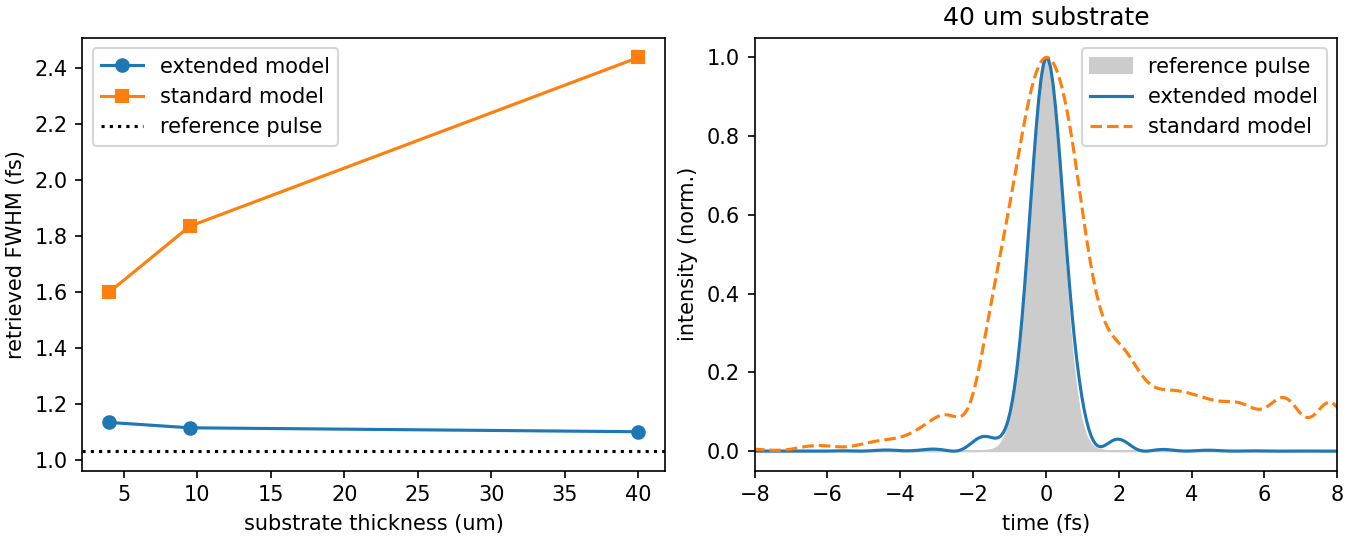

In [3]:
display(Image(filename="paper_thickness.png"))